# 01 — Dataset Exploration (Phase 1)

**NFL Big Data Bowl 2027** · structural and kinematic exploration of all nine competition files.

Scope (per `CLAUDE.md`, Phase 1): understand the data. **No models, no final research features, no hypothesis selection.**
Every number below is computed in this notebook from `data/interim/*.parquet`, a lossless typed cache of the raw CSVs
(row counts verified against the CSVs in §1). Raw data is never modified.

Sections: 1 Structure · 2 Combine tracking · 3 Game tracking · 4 Identity matching · 5 Research-opportunity probes · 6 Summary

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, polars as pl, matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap
from nfl_bdb.data.io import load, scan_raw, FILES, build_parquet_cache
from nfl_bdb.data.profiling import profile, key_report, add_kinematics, semantics_checks
from nfl_bdb.visualization import style
style.apply()
pl.Config.set_tbl_rows(70); pl.Config.set_tbl_width_chars(200); pl.Config.set_fmt_str_lengths(60); pl.Config.set_tbl_hide_dataframe_shape(True)
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
SPEED_CMAP = LinearSegmentedColormap.from_list("seq", style.SEQ_BLUE)
POS, PCOL = style.POSITION_ORDER, style.POSITION_COLOR
build_parquet_cache()
def save(fig, name): fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)

## 1 · Structural analysis of all nine files

In [2]:
rows = []
for name in FILES:
    n, prof = profile(load(name))
    n_csv = scan_raw(name).select(pl.len()).collect().item()
    lf = load(name); cols = lf.collect_schema().names()
    dup = n - lf.unique().select(pl.len()).collect().item()
    rows.append(dict(file=name, rows=n, rows_csv=n_csv, cols=len(cols), full_row_dups=dup,
                     nfl_ids=lf.select(pl.col("nfl_id").n_unique()).collect().item() if "nfl_id" in cols else None,
                     games=lf.select(pl.col("game_id").n_unique()).collect().item() if "game_id" in cols else None,
                     seasons_or_draft_years=lf.select(pl.col("season" if "season" in cols else "draft_year").unique().sort().cast(pl.Utf8).str.join(",")).collect().item()
                        if ("season" in cols or "draft_year" in cols) else None,
                     cells_null_pct=round(100*prof["nulls"].sum()/(n*len(cols)),2)))
inventory = pl.DataFrame(rows); inventory

file,rows,rows_csv,cols,full_row_dups,nfl_ids,games,seasons_or_draft_years,cells_null_pct
str,i64,i64,i64,i64,i64,i64,str,f64
"""combine_results""",510,510,18,0,510,null,"""2023,2024,2025""",14.04
"""combine_tracking""",463189,463189,14,0,510,null,"""2023,2024,2025""",0.0
"""game_tracking_2023""",3665443,3665443,12,0,156,333,null,7.78
"""game_tracking_2024""",7827944,7827944,12,0,318,334,null,7.78
"""game_tracking_2025""",11160903,11160903,12,0,448,334,null,7.78
"""games""",1002,1002,7,0,null,1002,"""2023,2024,2025""",0.0
"""player_career_successes""",510,510,9,0,510,null,null,0.0
"""player_play""",314197,314197,64,0,497,1001,null,44.18
"""players""",510,510,10,0,510,null,"""2023,2024,2025""",7.47


Per-column profile (dtype, missingness, cardinality) for every file:

In [3]:
for name in FILES:
    n, prof = profile(load(name))
    print(f"\n=== {name}  ({n:,} rows)"); print(prof)


=== combine_results  (510 rows)
┌──────────────────────────────┬─────────┬───────┬──────────┬──────────┐
│ column                       ┆ dtype   ┆ nulls ┆ null_pct ┆ n_unique │
│ ---                          ┆ ---     ┆ ---   ┆ ---      ┆ ---      │
│ str                          ┆ str     ┆ i64   ┆ f64      ┆ i64      │
╞══════════════════════════════╪═════════╪═══════╪══════════╪══════════╡
│ draft_year                   ┆ Int64   ┆ 0     ┆ 0.0      ┆ 3        │
│ nfl_id                       ┆ Int64   ┆ 0     ┆ 0.0      ┆ 510      │
│ combine_position             ┆ String  ┆ 0     ┆ 0.0      ┆ 5        │
│ combine_height               ┆ Float64 ┆ 0     ┆ 0.0      ┆ 95       │
│ combine_weight               ┆ Int64   ┆ 0     ┆ 0.0      ┆ 149      │
│ hand_size                    ┆ Float64 ┆ 0     ┆ 0.0      ┆ 27       │
│ arm_length                   ┆ Float64 ┆ 0     ┆ 0.0      ┆ 60       │
│ wing_span                    ┆ Float64 ┆ 0     ┆ 0.0      ┆ 114      │
│ ten_yd_split    


=== game_tracking_2023  (3,665,443 rows)
┌─────────┬──────────────────────────────────────────┬─────────┬──────────┬──────────┐
│ column  ┆ dtype                                    ┆ nulls   ┆ null_pct ┆ n_unique │
│ ---     ┆ ---                                      ┆ ---     ┆ ---      ┆ ---      │
│ str     ┆ str                                      ┆ i64     ┆ f64      ┆ i64      │
╞═════════╪══════════════════════════════════════════╪═════════╪══════════╪══════════╡
│ game_id ┆ Int64                                    ┆ 0       ┆ 0.0      ┆ 333      │
│ play_id ┆ Int64                                    ┆ 0       ┆ 0.0      ┆ 4649     │
│ nfl_id  ┆ Int64                                    ┆ 0       ┆ 0.0      ┆ 156      │
│ time    ┆ Datetime(time_unit='us', time_zone=None) ┆ 0       ┆ 0.0      ┆ 2032176  │
│ x       ┆ Float64                                  ┆ 0       ┆ 0.0      ┆ 12409    │
│ y       ┆ Float64                                  ┆ 0       ┆ 0.0      ┆ 6486     │
│


=== game_tracking_2024  (7,827,944 rows)
┌─────────┬──────────────────────────────────────────┬─────────┬──────────┬──────────┐
│ column  ┆ dtype                                    ┆ nulls   ┆ null_pct ┆ n_unique │
│ ---     ┆ ---                                      ┆ ---     ┆ ---      ┆ ---      │
│ str     ┆ str                                      ┆ i64     ┆ f64      ┆ i64      │
╞═════════╪══════════════════════════════════════════╪═════════╪══════════╪══════════╡
│ game_id ┆ Int64                                    ┆ 0       ┆ 0.0      ┆ 334      │
│ play_id ┆ Int64                                    ┆ 0       ┆ 0.0      ┆ 4719     │
│ nfl_id  ┆ Int64                                    ┆ 0       ┆ 0.0      ┆ 318      │
│ time    ┆ Datetime(time_unit='us', time_zone=None) ┆ 0       ┆ 0.0      ┆ 2534438  │
│ x       ┆ Float64                                  ┆ 0       ┆ 0.0      ┆ 12606    │
│ y       ┆ Float64                                  ┆ 0       ┆ 0.0      ┆ 6622     │
│


=== game_tracking_2025  (11,160,903 rows)
┌─────────┬──────────────────────────────────────────┬──────────┬──────────┬──────────┐
│ column  ┆ dtype                                    ┆ nulls    ┆ null_pct ┆ n_unique │
│ ---     ┆ ---                                      ┆ ---      ┆ ---      ┆ ---      │
│ str     ┆ str                                      ┆ i64      ┆ f64      ┆ i64      │
╞═════════╪══════════════════════════════════════════╪══════════╪══════════╪══════════╡
│ game_id ┆ Int64                                    ┆ 0        ┆ 0.0      ┆ 334      │
│ play_id ┆ Int64                                    ┆ 0        ┆ 0.0      ┆ 4746     │
│ nfl_id  ┆ Int64                                    ┆ 0        ┆ 0.0      ┆ 448      │
│ time    ┆ Datetime(time_unit='us', time_zone=None) ┆ 0        ┆ 0.0      ┆ 2652110  │
│ x       ┆ Float64                                  ┆ 0        ┆ 0.0      ┆ 12830    │
│ y       ┆ Float64                                  ┆ 0        ┆ 0.0      ┆ 


=== player_play  (314,197 rows)
┌───────────────────────────────────────┬─────────┬────────┬──────────┬──────────┐
│ column                                ┆ dtype   ┆ nulls  ┆ null_pct ┆ n_unique │
│ ---                                   ┆ ---     ┆ ---    ┆ ---      ┆ ---      │
│ str                                   ┆ str     ┆ i64    ┆ f64      ┆ i64      │
╞═══════════════════════════════════════╪═════════╪════════╪══════════╪══════════╡
│ game_id                               ┆ Int64   ┆ 0      ┆ 0.0      ┆ 1001     │
│ play_id                               ┆ Int64   ┆ 0      ┆ 0.0      ┆ 4931     │
│ team_abbr                             ┆ String  ┆ 0      ┆ 0.0      ┆ 33       │
│ nfl_id                                ┆ Int64   ┆ 0      ┆ 0.0      ┆ 497      │
│ lined_up_position                     ┆ String  ┆ 1383   ┆ 0.44     ┆ 18       │
│ play_description                      ┆ String  ┆ 0      ┆ 0.0      ┆ 114899   │
│ quarter                               ┆ Int64   ┆ 0 

### Candidate primary keys
Tested empirically (rows vs. distinct key tuples). `combine_tracking` needs `entity_type` in the key because each WR/TE catching rep also carries a `BALL` row per frame tagged with the *receiver's* `nfl_id`.

In [4]:
kr = pl.DataFrame([
    key_report(load("players"), ["nfl_id"]), key_report(load("combine_results"), ["nfl_id"]),
    key_report(load("player_career_successes"), ["nfl_id"]), key_report(load("games"), ["game_id"]),
    key_report(load("combine_tracking"), ["nfl_id","time"]),
    key_report(load("combine_tracking"), ["nfl_id","time","entity_type"]),
    key_report(load("combine_tracking"), ["event_id","time","entity_type"]),
    key_report(load("player_play"), ["game_id","play_id"]), key_report(load("player_play"), ["game_id","play_id","nfl_id"]),
    *[key_report(load(f"game_tracking_{y}"), ["game_id","play_id","nfl_id","time"]) for y in (2023,2024,2025)],
]); kr

key,rows,unique,duplicates,is_key
str,i64,i64,i64,bool
"""nfl_id""",510,510,0,true
"""nfl_id""",510,510,0,true
"""nfl_id""",510,510,0,true
"""game_id""",1002,1002,0,true
"""nfl_id, time""",463189,431094,32095,false
"""nfl_id, time, entity_type""",463189,463189,0,true
"""event_id, time, entity_type""",463189,463189,0,true
"""game_id, play_id""",314197,114954,199243,false
"""game_id, play_id, nfl_id""",314197,314197,0,true


### Relationships (referential integrity of `nfl_id` and `game_id`)

In [5]:
ids = {n: set(load(n).select("nfl_id").unique().collect()["nfl_id"]) for n in FILES if n != "games"}
base = ids["players"]
pl.DataFrame([dict(file=k, nfl_ids=len(v), in_players=len(v & base), orphan=len(v - base), equals_players=(v == base)) for k, v in ids.items()])

file,nfl_ids,in_players,orphan,equals_players
str,i64,i64,i64,bool
"""combine_results""",510,510,0,true
"""combine_tracking""",510,510,0,true
"""game_tracking_2023""",156,156,0,false
"""game_tracking_2024""",318,318,0,false
"""game_tracking_2025""",448,448,0,false
"""player_career_successes""",510,510,0,true
"""player_play""",497,497,0,false
"""players""",510,510,0,true


In [6]:
games = load("games", lazy=False)
print(games.group_by("season","season_type").agg(pl.len().alias("games"), pl.col("week").min().alias("wk_min"), pl.col("week").max().alias("wk_max")).sort("season","season_type"))
for y in (2023,2024,2025):
    g = load(f"game_tracking_{y}").select("game_id").unique().collect().join(games, on="game_id", how="left")
    print(y, "tracking games:", g.height, "| orphan game_ids:", g["season"].null_count(), "| all from season", g["season"].unique().to_list())
pp = load("player_play")
print("games.csv games without any player_play/tracking rows:", games.join(pp.select("game_id").unique().collect(), on="game_id", how="anti")["game_id"].to_list())

┌────────┬─────────────┬───────┬────────┬────────┐
│ season ┆ season_type ┆ games ┆ wk_min ┆ wk_max │
│ ---    ┆ ---         ┆ ---   ┆ ---    ┆ ---    │
│ i64    ┆ str         ┆ u32   ┆ i64    ┆ i64    │
╞════════╪═════════════╪═══════╪════════╪════════╡
│ 2023   ┆ POST        ┆ 13    ┆ 19     ┆ 23     │
│ 2023   ┆ PRE         ┆ 49    ┆ 0      ┆ 3      │
│ 2023   ┆ REG         ┆ 272   ┆ 1      ┆ 18     │
│ 2024   ┆ POST        ┆ 13    ┆ 19     ┆ 23     │
│ 2024   ┆ PRE         ┆ 49    ┆ 0      ┆ 3      │
│ 2024   ┆ REG         ┆ 272   ┆ 1      ┆ 18     │
│ 2025   ┆ POST        ┆ 13    ┆ 19     ┆ 23     │
│ 2025   ┆ PRE         ┆ 49    ┆ 0      ┆ 3      │
│ 2025   ┆ REG         ┆ 272   ┆ 1      ┆ 18     │
└────────┴─────────────┴───────┴────────┴────────┘
2023 tracking games: 333 | orphan game_ids: 0 | all from season [2023]
2024 tracking games: 334 | orphan game_ids: 0 | all from season [2024]
2025 tracking games: 334 | orphan game_ids: 0 | all from season [2025]
games.csv games withou

```
players (510, PK nfl_id) ──1:1── combine_results ──1:1── player_career_successes
   │1:N                                  
   ├── combine_tracking   (nfl_id; event_id = one drill attempt; PLAYER + BALL entities)
   ├── player_play        (game_id, play_id, nfl_id) ──N:1── games (game_id)
   └── game_tracking_YYYY (game_id, play_id, nfl_id, time) ──≈1:1 per player-play── player_play
```
Tracking ↔ `player_play` agreement at the (game, play, player) level:

In [7]:
pp_all = load("player_play").select("game_id","play_id","nfl_id")
out = []
for y in (2023,2024,2025):
    gt = load(f"game_tracking_{y}").select("game_id","play_id","nfl_id").unique()
    ppy = pp_all.join(load("games").filter(pl.col("season")==y).select("game_id"), on="game_id")
    out.append(dict(season=y, tracked_player_plays=gt.select(pl.len()).collect().item(),
        player_play_rows=ppy.select(pl.len()).collect().item(),
        tracked_not_in_player_play=gt.join(ppy, on=["game_id","play_id","nfl_id"], how="anti").select(pl.len()).collect().item(),
        player_play_without_tracking=ppy.join(gt, on=["game_id","play_id","nfl_id"], how="anti").select(pl.len()).collect().item()))
pl.DataFrame(out)

season,tracked_player_plays,player_play_rows,tracked_not_in_player_play,player_play_without_tracking
i64,i64,i64,i64,i64
2023,50911,50755,449,293
2024,108720,108524,857,661
2025,155313,154918,1191,796


## 2 · Combine tracking (`combine_tracking.csv`)
### 2.1 Variable semantics — provided or derived?
We test each provided channel against quantities derived from the raw `x, y` positions.

In [8]:
ct = load("combine_tracking", lazy=False)
CP = ct.filter(pl.col("entity_type")=="PLAYER")
CB = ct.filter(pl.col("entity_type")=="BALL")
ck = add_kinematics(CP, "event_id")
print("Combine PLAYER rows:", CP.height, "| BALL rows:", CB.height)
semantics_checks(ck)

Combine PLAYER rows: 431094 | BALL rows: 32095


check,pearson_r,median_ratio
str,f64,f64
"""s vs 10*step (yd/s)""",0.998123,1.003625
"""dis vs step (yd)""",0.951776,0.462073
"""a vs |vector accel|""",0.99336,0.963827
"""a vs |ds/dt| (tangential)""",0.625381,1.196439
"""dir vs atan2(dx,dy) NGS [median |deg|]""",null,1.193977
"""dir vs atan2(dy,dx) math [median |deg|]""",null,90.224248


In [9]:
gs = load("game_tracking_2025").head(2_000_000).collect()
gs = gs.with_columns(pl.concat_str([pl.col("game_id"), pl.col("play_id"), pl.col("nfl_id")], separator="_").alias("k"))
gk = add_kinematics(gs, "k")
semantics_checks(gk)

check,pearson_r,median_ratio
str,f64,f64
"""s vs 10*step (yd/s)""",0.995952,0.983617
"""dis vs step (yd)""",0.999583,0.998793
"""a vs |vector accel|""",0.878591,0.775862
"""a vs |ds/dt| (tangential)""",0.616111,1.144444
"""dir vs atan2(dx,dy) NGS [median |deg|]""",null,1.127373
"""dir vs atan2(dy,dx) math [median |deg|]""",null,90.13


**Reading the checks**
* `x, y` are in yards; `s` is speed in yd/s (ratio to finite-difference speed ≈ 1.00 in both sources).
* `dir` follows the NGS convention (0° = +y, clockwise) in both sources (median error ≈ 1°).
* `a` is an **unsigned acceleration magnitude** — never negative (outside one faulty game, §3). In combine data it matches the magnitude of the full acceleration vector |dv/dt| almost exactly (r ≈ 0.99); in game data the match is looser (r ≈ 0.88, ratio ≈ 0.78), consistent with different smoothing. Against tangential |ds/dt| it is only r ≈ 0.6 in both. It therefore mixes speeding up, braking and turning. **Deceleration is not provided and must be derived** (e.g. signed ds/dt).
* `dis`: in **game** data it equals the per-frame displacement (ratio ≈ 1.00). In **combine** data it is ≈ 0.46× the per-frame displacement — a different definition or sampling basis. **Combine `dis` must not be compared with game `dis`;** derive distance from `x, y` instead.
* Orientation `o` exists only in game data.

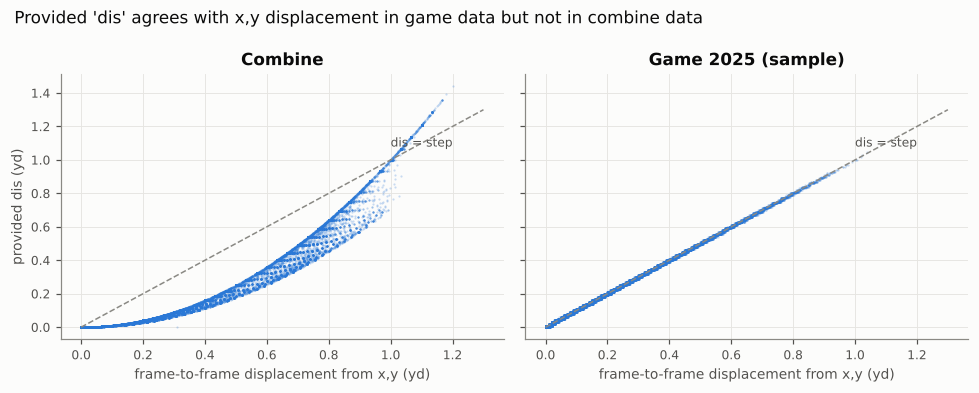

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharex=True, sharey=True)
for ax, (lab, d) in zip(axes, [("Combine", ck), ("Game 2025 (sample)", gk)]):
    d = d.drop_nulls("step").filter(pl.col("step") < 1.3).sample(20000, seed=1)
    ax.scatter(d["step"], d["dis"], s=2, alpha=.25, color=style.SERIES[0], linewidths=0)
    ax.plot([0,1.3],[0,1.3], color=style.MUTED, lw=1, ls="--"); ax.text(1.0, 1.08, "dis = step", color=style.TEXT2, fontsize=8)
    ax.set_title(lab); ax.set_xlabel("frame-to-frame displacement from x,y (yd)")
axes[0].set_ylabel("provided dis (yd)")
fig.suptitle("Provided 'dis' agrees with x,y displacement in game data but not in combine data", fontsize=11, x=0.02, ha="left")
fig.tight_layout(); save(fig, "fig01_dis_semantics")

### 2.2 Time representation and sampling

In [11]:
dt = CP.sort("event_id","time").select(pl.col("time").diff().over("event_id").dt.total_milliseconds().alias("dt")).drop_nulls()
print("Δt between consecutive frames within an attempt (ms):", dt.group_by("dt").len().rows())
print("All timestamps on a 100 ms grid:", (CP["time"].dt.millisecond() % 100 == 0).all())
print("Players per event_id:", CP.group_by("event_id").agg(pl.col("nfl_id").n_unique())["nfl_id"].unique().to_list(),
      "| events:", CP["event_id"].n_unique())
print("Combine dates:", sorted(set(CP["time"].dt.date().to_list())))
print("event_id formats:", CP.select(pl.col("event_id").str.replace_all(r"[0-9a-f]", "h").str.replace_all(r"h+", "h").alias("f"), "draft_year").unique().sort("draft_year").rows())

Δt between consecutive frames within an attempt (ms): [(100, 424784)]
All timestamps on a 100 ms grid: True
Players per event_id: [1] | events: 6310
Combine dates: [datetime.date(2023, 3, 2), datetime.date(2023, 3, 3), datetime.date(2023, 3, 4), datetime.date(2023, 3, 5), datetime.date(2024, 2, 29), datetime.date(2024, 3, 1), datetime.date(2024, 3, 2), datetime.date(2024, 3, 3), datetime.date(2025, 2, 27), datetime.date(2025, 2, 28), datetime.date(2025, 3, 1), datetime.date(2025, 3, 2)]


event_id formats: [('h-h', 2023), ('h_h_h', 2024), ('h_h_h', 2025)]


Time is an absolute wall-clock timestamp (ISO 8601, no timezone) at exactly **10 Hz** with **no dropped frames** inside any attempt. Each `event_id` is one player's single attempt at a drill. There is no explicit start/stop marker (no `event` column). The 2023 `event_id` format differs from the 2024–25 one.

### 2.3 Drills and positions

In [12]:
cr = load("combine_results", lazy=False)
CPp = CP.join(cr.select("nfl_id","combine_position"), on="nfl_id")
mat = CPp.group_by("drill_type","combine_position").agg(pl.col("nfl_id").n_unique().alias("n")).pivot(on="combine_position", index="drill_type", values="n").fill_null(0).sort("drill_type")
mat = mat.select(["drill_type"] + [p for p in POS if p in mat.columns])
print(cr.group_by("combine_position").len().sort("combine_position")); mat

┌──────────────────┬─────┐
│ combine_position ┆ len │
│ ---              ┆ --- │
│ str              ┆ u32 │
╞══════════════════╪═════╡
│ DB               ┆ 122 │
│ DL               ┆ 118 │
│ OL               ┆ 121 │
│ TE               ┆ 42  │
│ WR               ┆ 107 │
└──────────────────┴─────┘


drill_type,WR,TE,OL,DL,DB
str,u32,u32,u32,u32,u32
"""FORTY_YARD_DASH""",94,34,95,93,102
"""SHORT_SHUTTLE""",29,21,54,38,28
"""SKILL_DRILLS_DB""",0,0,0,0,122
"""SKILL_DRILLS_DL""",0,0,0,114,0
"""SKILL_DRILLS_LB""",0,0,0,4,0
"""SKILL_DRILLS_OL""",0,0,121,0,0
"""SKILL_DRILLS_TE""",0,42,0,0,0
"""SKILL_DRILLS_WR""",107,0,0,0,0
"""THREE_CONE_DRILL""",24,19,48,45,24


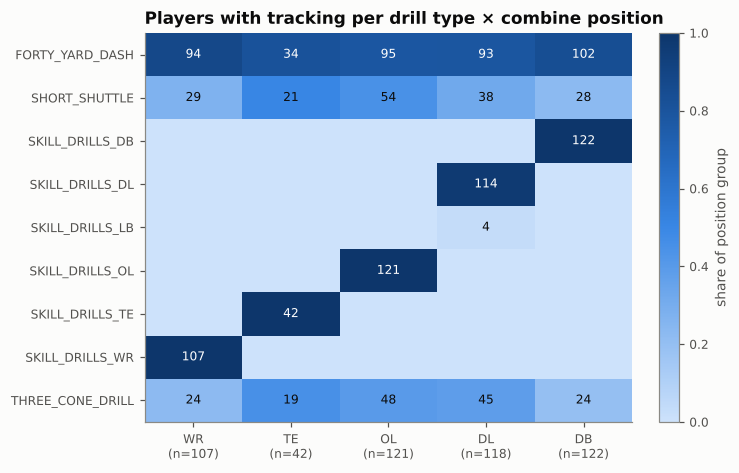

In [13]:
M = mat.select(POS).to_numpy(); tot = cr.group_by("combine_position").len().sort("combine_position")
totd = dict(tot.rows())
fig, ax = plt.subplots(figsize=(6.8, 4.4))
frac = M / np.array([totd[p] for p in POS])
im = ax.imshow(frac, cmap=SPEED_CMAP, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(POS)), [f"{p}\n(n={totd[p]})" for p in POS]); ax.set_yticks(range(M.shape[0]), mat["drill_type"].to_list())
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if M[i,j]: ax.text(j, i, int(M[i,j]), ha="center", va="center", fontsize=8, color=style.TEXT if frac[i,j] < .55 else "white")
ax.grid(False); ax.set_title("Players with tracking per drill type × combine position", loc="left")
cb = fig.colorbar(im, ax=ax, fraction=.04); cb.set_label("share of position group", color=style.TEXT2)
fig.tight_layout(); save(fig, "fig02_drill_position")

In [14]:
drills = CP.group_by("drill_type","drill_name").agg(pl.col("nfl_id").n_unique().alias("players"), pl.col("event_id").n_unique().alias("attempts"),
            pl.len().alias("frames"), pl.col("draft_year").unique().sort().cast(pl.Utf8).str.join(",").alias("years")).sort("drill_type","drill_name")
drills

drill_type,drill_name,players,attempts,frames,years
str,str,u32,u32,u32,str
"""FORTY_YARD_DASH""","""FORTY_YARD_DASH""",418,793,41500,"""2023,2024,2025"""
"""SHORT_SHUTTLE""","""SHORT_SHUTTLE""",170,223,11690,"""2023,2024,2025"""
"""SKILL_DRILLS_DB""","""BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL""",122,124,8422,"""2023,2024,2025"""
"""SKILL_DRILLS_DB""","""BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION""",122,241,21569,"""2023,2024,2025"""
"""SKILL_DRILLS_DB""","""BOX_DRILL""",122,125,9439,"""2023,2024,2025"""
"""SKILL_DRILLS_DB""","""GAUNTLET_DRILL""",119,123,12253,"""2023,2024,2025"""
"""SKILL_DRILLS_DB""","""LINE""",33,50,3552,"""2023"""
"""SKILL_DRILLS_DB""","""LINE_DRILL""",85,167,11895,"""2024,2025"""
"""SKILL_DRILLS_DB""","""TERYL_AUSTIN_DRILL_1""",101,103,7765,"""2023,2024,2025"""


**Naming inconsistencies** — several drills appear under two names, split by year (must be harmonised before any cross-year analysis):

In [15]:
pairs = [("PASS_PRO-MIRROR_DRILL","PASS_PRO_MIRROR_DRILL"),("LINE","LINE_DRILL"),("OVER_SHOULDER_ADJUST","OVER_THE_SHOULDER_ADJUST"),("SPEED_OUT_LEFT","SPEED_OUT_ROUTE_LEFT")]
drills.filter(pl.col("drill_name").is_in([x for p in pairs for x in p])).select("drill_type","drill_name","players","years")

drill_type,drill_name,players,years
str,str,u32,str
"""SKILL_DRILLS_DB""","""LINE""",33,"""2023"""
"""SKILL_DRILLS_DB""","""LINE_DRILL""",85,"""2024,2025"""
"""SKILL_DRILLS_OL""","""PASS_PRO-MIRROR_DRILL""",84,"""2024,2025"""
"""SKILL_DRILLS_OL""","""PASS_PRO_MIRROR_DRILL""",37,"""2023"""
"""SKILL_DRILLS_TE""","""OVER_SHOULDER_ADJUST""",30,"""2024,2025"""
"""SKILL_DRILLS_TE""","""OVER_THE_SHOULDER_ADJUST""",12,"""2023"""
"""SKILL_DRILLS_WR""","""OVER_SHOULDER_ADJUST""",100,"""2023,2024,2025"""
"""SKILL_DRILLS_WR""","""SPEED_OUT_LEFT""",31,"""2024"""
"""SKILL_DRILLS_WR""","""SPEED_OUT_ROUTE_LEFT""",76,"""2023,2025"""


### 2.4 Observations per player and drill; sequence completeness

In [16]:
ev = CP.group_by("event_id","nfl_id","drill_type","drill_name","attempt").agg(pl.len().alias("frames"),
        ((pl.col("time").max()-pl.col("time").min()).dt.total_milliseconds()/100 + 1).alias("span_frames"))
print("events with missing frames (span != frames):", (ev["span_frames"] != ev["frames"]).sum(), "of", ev.height)
print(ev.group_by("drill_type").agg(pl.len().alias("attempts"), pl.col("frames").min().alias("min"), pl.col("frames").median().alias("median"),
      pl.col("frames").quantile(.95).alias("p95"), pl.col("frames").max().alias("max")).sort("drill_type"))
per_player = ev.group_by("nfl_id","drill_type").agg(pl.len().alias("attempts"), pl.col("frames").sum().alias("frames"))
print(per_player.group_by("drill_type").agg(pl.col("attempts").median().alias("median_attempts_per_player"), pl.col("frames").median().alias("median_frames_per_player")).sort("drill_type"))
tot_pp = CP.group_by("nfl_id").agg(pl.len().alias("frames"), pl.col("event_id").n_unique().alias("attempts"), pl.col("drill_type").n_unique().alias("drill_types"))
print("Per player totals:", tot_pp.select([pl.col(c).quantile(q).alias(f"{c}_p{int(q*100)}") for c in ["frames","attempts"] for q in (0,.5,1)]).row(0, named=True))
print("Players by # drill types:", tot_pp["drill_types"].value_counts().sort("drill_types").rows())
print("(player, drill, attempt) recorded as 2 separate events:", ev.group_by("nfl_id","drill_name","attempt").len().filter(pl.col("len")>1).height)

events with missing frames (span != frames): 0 of 6310
┌──────────────────┬──────────┬─────┬────────┬───────┬─────┐
│ drill_type       ┆ attempts ┆ min ┆ median ┆ p95   ┆ max │
│ ---              ┆ ---      ┆ --- ┆ ---    ┆ ---   ┆ --- │
│ str              ┆ u32      ┆ u32 ┆ f64    ┆ f64   ┆ u32 │
╞══════════════════╪══════════╪═════╪════════╪═══════╪═════╡
│ FORTY_YARD_DASH  ┆ 793      ┆ 45  ┆ 51.0   ┆ 59.0  ┆ 90  │
│ SHORT_SHUTTLE    ┆ 223      ┆ 11  ┆ 51.0   ┆ 64.0  ┆ 202 │
│ SKILL_DRILLS_DB  ┆ 1170     ┆ 41  ┆ 77.0   ┆ 114.0 ┆ 173 │
│ SKILL_DRILLS_DL  ┆ 1007     ┆ 33  ┆ 74.0   ┆ 126.0 ┆ 170 │
│ SKILL_DRILLS_LB  ┆ 37       ┆ 44  ┆ 91.0   ┆ 124.0 ┆ 128 │
│ SKILL_DRILLS_OL  ┆ 910      ┆ 22  ┆ 50.0   ┆ 160.0 ┆ 209 │
│ SKILL_DRILLS_TE  ┆ 438      ┆ 35  ┆ 63.0   ┆ 107.0 ┆ 123 │
│ SKILL_DRILLS_WR  ┆ 1529     ┆ 21  ┆ 62.0   ┆ 93.0  ┆ 150 │
│ THREE_CONE_DRILL ┆ 203      ┆ 10  ┆ 79.0   ┆ 90.0  ┆ 101 │
└──────────────────┴──────────┴─────┴────────┴───────┴─────┘
┌──────────────────┬──────────

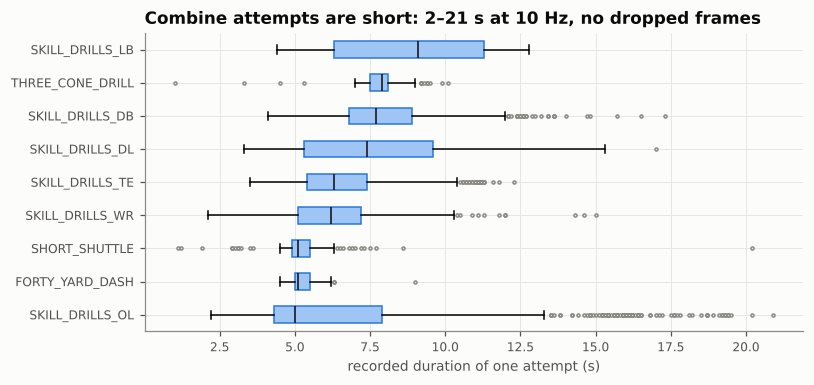

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
order = ev.group_by("drill_type").agg(pl.col("frames").median()).sort("frames")["drill_type"].to_list()
data = [ev.filter(pl.col("drill_type")==d)["frames"].to_numpy()/10 for d in order]
bp = ax.boxplot(data, orientation="horizontal", widths=.5, patch_artist=True, showfliers=True, flierprops=dict(markersize=2, markeredgecolor=style.MUTED),
                medianprops=dict(color=style.TEXT), boxprops=dict(facecolor=style.SEQ_BLUE[1], edgecolor=style.SERIES[0]))
ax.set_yticks(range(1, len(order)+1), order); ax.set_xlabel("recorded duration of one attempt (s)")
ax.set_title("Combine attempts are short: 2–21 s at 10 Hz, no dropped frames", loc="left")
fig.tight_layout(); save(fig, "fig03_attempt_duration")

### 2.5 The actual movement sequences
Paths for one representative attempt per drill family, coloured by instantaneous speed. Catching drills overlay the ball track.

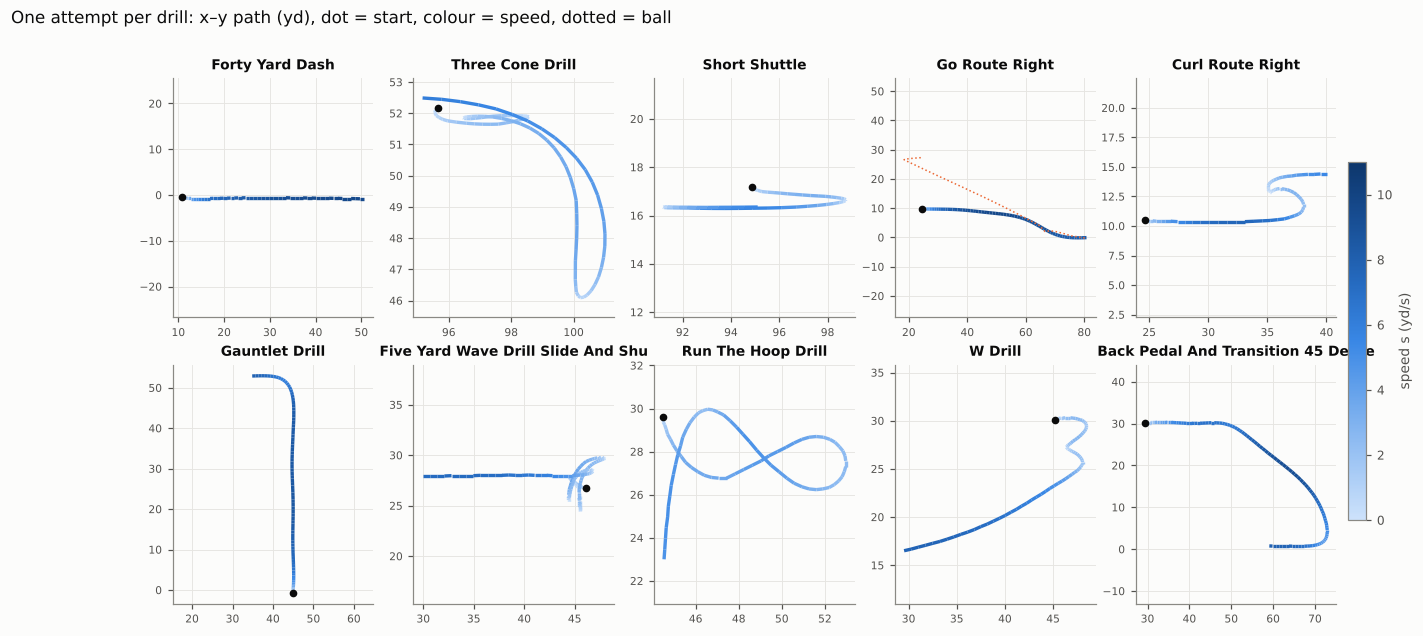

In [18]:
def path(ax, d, title, ball=None):
    xy = d.select("x","y").to_numpy(); s = d["s"].to_numpy()
    seg = np.stack([xy[:-1], xy[1:]], axis=1)
    lc = LineCollection(seg, cmap=SPEED_CMAP, norm=plt.Normalize(0, 11), linewidths=2.2); lc.set_array(s[:-1]); ax.add_collection(lc)
    ax.plot(*xy[0], "o", color=style.TEXT, ms=4); 
    if ball is not None and ball.height: ax.plot(ball["x"], ball["y"], color=style.SERIES[1], lw=1, ls=":", label="ball")
    ax.set_title(title, fontsize=9); ax.set_aspect("equal", adjustable="datalim"); ax.autoscale_view()
    ax.tick_params(labelsize=7); return lc
rng = np.random.default_rng(7)
picks = ["FORTY_YARD_DASH","THREE_CONE_DRILL","SHORT_SHUTTLE","GO_ROUTE_RIGHT","CURL_ROUTE_RIGHT","GAUNTLET_DRILL",
         "FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE","RUN_THE_HOOP_DRILL","W_DRILL","BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION"]
fig, axes = plt.subplots(2, 5, figsize=(14, 6.2))
for ax, dn in zip(axes.flat, picks):
    evs = ev.filter((pl.col("drill_name")==dn)&(pl.col("frames")>=ev.filter(pl.col("drill_name")==dn)["frames"].median()))["event_id"].to_list()
    e = evs[int(rng.integers(len(evs)))]
    lc = path(ax, CP.filter(pl.col("event_id")==e).sort("time"), dn.replace("_"," ").title()[:34], CB.filter(pl.col("event_id")==e).sort("time"))
cb = fig.colorbar(lc, ax=axes, fraction=.015, pad=.01); cb.set_label("speed s (yd/s)", color=style.TEXT2)
fig.suptitle("One attempt per drill: x–y path (yd), dot = start, colour = speed, dotted = ball", x=0.02, ha="left", fontsize=11)
save(fig, "fig04_drill_paths")

**40-yard dash time series.** Speed and *derived* signed tangential acceleration (ds/dt) for all attempts, aligned at movement onset (first frame with s > 0.3 yd/s). Two panels rather than a dual axis.

Attempts: 793 | recordings extend past the finish: median samples after peak speed = 5.0


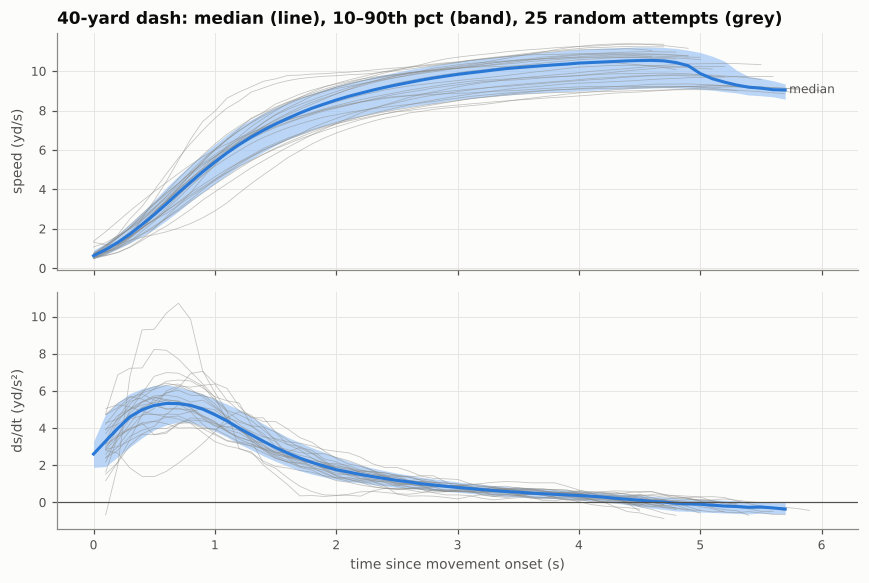

In [19]:
f40 = ck.filter(pl.col("drill_type")=="FORTY_YARD_DASH").with_columns(pl.int_range(pl.len()).over("event_id").alias("i"))
onset = f40.filter(pl.col("s")>0.3).group_by("event_id").agg(pl.col("i").min().alias("i0"))
f40 = f40.join(onset, on="event_id").with_columns(((pl.col("i")-pl.col("i0"))/10).alias("t")).filter(pl.col("t").is_between(-0.5, 6))
q = f40.group_by("t").agg([pl.col("s").quantile(p).alias(f"s{int(p*100)}") for p in (.1,.5,.9)]+[pl.col("a_tan").quantile(p).alias(f"a{int(p*100)}") for p in (.1,.5,.9)]+[pl.len()]).filter(pl.col("len")>50).sort("t")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 5.4), sharex=True)
for e in f40["event_id"].unique().sample(25, seed=3).to_list():
    d = f40.filter(pl.col("event_id")==e); a1.plot(d["t"], d["s"], color=style.MUTED, lw=.5, alpha=.5); a2.plot(d["t"], d["a_tan"], color=style.MUTED, lw=.5, alpha=.5)
a1.fill_between(q["t"], q["s10"], q["s90"], color=style.SEQ_BLUE[1], alpha=.7, lw=0); a1.plot(q["t"], q["s50"], color=style.SERIES[0], lw=2)
a2.fill_between(q["t"], q["a10"], q["a90"], color=style.SEQ_BLUE[1], alpha=.7, lw=0); a2.plot(q["t"], q["a50"], color=style.SERIES[0], lw=2)
a2.axhline(0, color=style.TEXT2, lw=.8)
a1.set_ylabel("speed (yd/s)"); a2.set_ylabel("ds/dt (yd/s²)"); a2.set_xlabel("time since movement onset (s)")
a1.set_title("40-yard dash: median (line), 10–90th pct (band), 25 random attempts (grey)", loc="left")
a1.text(q["t"][-1], q["s50"][-1], " median", color=style.TEXT2, fontsize=8, va="center")
fig.tight_layout(); save(fig, "fig05_forty_timeseries")
print("Attempts:", f40["event_id"].n_unique(), "| recordings extend past the finish: median samples after peak speed =",
      f40.group_by("event_id").agg((pl.len() - pl.col("s").arg_max()).alias("after"))["after"].median())

Recordings stop roughly 0.5 s after peak speed (median 5 frames), so the **post-finish braking is largely not captured** in the 40 — braking must be studied in the agility and skill drills instead (§5).

**Validation against the official stopwatch time.** A naive tracking-derived 40 time (onset at s > 0.3 yd/s → first frame 40 yd further along the run axis; best of a player's attempts) versus the official `forty`:

n=381  Pearson r=0.906  median(track - official)=0.35s


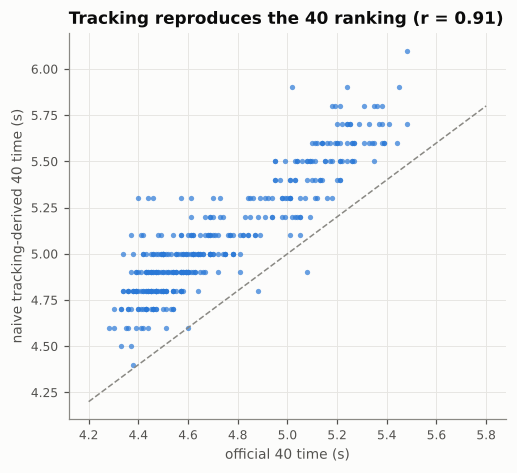

In [20]:
def t40(g):
    x, y, s = g["x"].to_numpy(), g["y"].to_numpy(), g["s"].to_numpy()
    ax_ = x if np.ptp(x) > np.ptp(y) else y; p = (ax_ - ax_[0]) * np.sign(ax_[-1] - ax_[0])
    mv = np.where(s > 0.3)[0]
    if not len(mv): return None
    hit = np.where(p >= p[mv[0]] + 40)[0]
    return (hit[0] - mv[0]) / 10 if len(hit) else None
r = [(k[1], t40(g.sort("time"))) for k, g in CP.filter(pl.col("drill_type")=="FORTY_YARD_DASH").group_by(["event_id","nfl_id"])]
tt = pl.DataFrame(r, schema=["nfl_id","t40_track"], orient="row").drop_nulls().group_by("nfl_id").agg(pl.col("t40_track").min())
j40 = tt.join(cr.select("nfl_id","forty","combine_position"), on="nfl_id").drop_nulls()
rho = j40.select(pl.corr("t40_track","forty")).item()
print(f"n={j40.height}  Pearson r={rho:.3f}  median(track - official)={(j40['t40_track']-j40['forty']).median():.2f}s")
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.scatter(j40["forty"], j40["t40_track"], s=12, color=style.SERIES[0], alpha=.7, linewidths=0)
lo, hi = 4.2, 5.8; ax.plot([lo,hi],[lo,hi], color=style.MUTED, ls="--", lw=1)
ax.set_xlabel("official 40 time (s)"); ax.set_ylabel("naive tracking-derived 40 time (s)")
ax.set_title(f"Tracking reproduces the 40 ranking (r = {rho:.2f})", loc="left")
fig.tight_layout(); save(fig, "fig06_forty_validation")

The systematic +0.3 s offset reflects the crude onset rule (the official clock starts on the athlete's first movement from a 3-point stance; our s > 0.3 yd/s threshold and 0.1 s grid are not equivalent). The high correlation confirms the tracking captures the sprint faithfully; it is a sanity check, not a feature.

**Change of direction in the 3-cone drill:** speed and heading over time for one attempt — the turns appear as speed minima coinciding with rapid heading change.

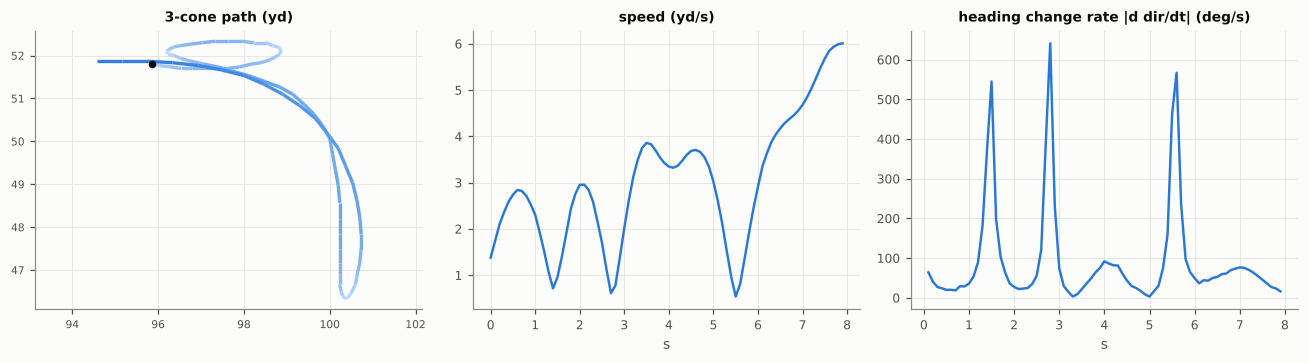

In [21]:
e = ev.filter((pl.col("drill_type")=="THREE_CONE_DRILL")&(pl.col("frames").is_between(70, 90)))["event_id"][0]
d = ck.filter(pl.col("event_id")==e).with_columns(((pl.int_range(pl.len()))/10).alias("t"),
        (((pl.col("dir").diff()+180)%360-180).abs()*10).alias("turn_rate"))
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
path(axs[0], d, "3-cone path (yd)")
axs[1].plot(d["t"], d["s"], color=style.SERIES[0]); axs[1].set_title("speed (yd/s)", fontsize=9); axs[1].set_xlabel("s")
axs[2].plot(d["t"], d["turn_rate"], color=style.SERIES[0]); axs[2].set_title("heading change rate |d dir/dt| (deg/s)", fontsize=9); axs[2].set_xlabel("s")
fig.tight_layout(); save(fig, "fig07_three_cone_cod")

Heading-rate spikes are noisy at low speed (direction is ill-defined when s → 0) — any change-of-direction work must handle this explicitly.

## 3 · NFL game tracking (2023–2025)

In [22]:
k3 = ["game_id","play_id","nfl_id"]
rows, seqs = [], {}
for y in (2023,2024,2025):
    gt = load(f"game_tracking_{y}")
    sq = (gt.sort(k3+["time"]).with_columns(pl.col("time").diff().over(k3).dt.total_milliseconds().alias("dt"))
            .group_by(k3).agg(pl.len().alias("frames"), (pl.col("dt")>100).sum().alias("gaps"),
                              pl.col("event").drop_nulls().first().alias("first_event"), pl.col("event").drop_nulls().last().alias("last_event"))).collect()
    seqs[y] = sq.with_columns(pl.lit(y).alias("season"))
    rows.append(dict(season=y, rows=gt.select(pl.len()).collect().item(), games=sq["game_id"].n_unique(), plays=sq.select("game_id","play_id").n_unique(),
        players=sq["nfl_id"].n_unique(), player_plays=sq.height, median_frames=sq["frames"].median(), max_frames=sq["frames"].max(),
        player_plays_with_gaps=(sq["gaps"]>0).sum(), starts_at_snap_pct=round(100*(sq["first_event"]=="ball_snap").mean(),1),
        event_null_pct=round(100*gt.select(pl.col("event").is_null().mean()).collect().item(),1)))
pl.DataFrame(rows)

season,rows,games,plays,players,player_plays,median_frames,max_frames,player_plays_with_gaps,starts_at_snap_pct,event_null_pct
i64,i64,i64,i64,i64,i64,f64,i64,i64,f64,f64
2023,3665443,333,31690,156,50911,69.0,340,3,92.6,93.4
2024,7827944,334,40331,318,108720,69.0,688,3,94.5,93.3
2025,11160903,334,42544,448,155313,69.0,241,2,93.4,93.4


In [23]:
S = pl.concat(seqs.values()).join(games.select("game_id","season_type"), on="game_id")
print(S.group_by("season","season_type").agg(pl.len().alias("player_plays"), pl.col("frames").sum().alias("frames")).sort("season","season_type"))
print("First event of each tracked sequence:", S["first_event"].value_counts().sort("count", descending=True).head(6).rows())
print("Last event:", S["last_event"].value_counts().sort("count", descending=True).head(8).rows())

┌────────┬─────────────┬──────────────┬─────────┐
│ season ┆ season_type ┆ player_plays ┆ frames  │
│ ---    ┆ ---         ┆ ---          ┆ ---     │
│ i32    ┆ str         ┆ u32          ┆ u32     │
╞════════╪═════════════╪══════════════╪═════════╡
│ 2023   ┆ POST        ┆ 1558         ┆ 114085  │
│ 2023   ┆ PRE         ┆ 10207        ┆ 728894  │
│ 2023   ┆ REG         ┆ 39146        ┆ 2822464 │
│ 2024   ┆ POST        ┆ 4291         ┆ 309862  │
│ 2024   ┆ PRE         ┆ 18210        ┆ 1292587 │
│ 2024   ┆ REG         ┆ 86219        ┆ 6225495 │
│ 2025   ┆ POST        ┆ 7196         ┆ 523090  │
│ 2025   ┆ PRE         ┆ 22375        ┆ 1577661 │
│ 2025   ┆ REG         ┆ 125742       ┆ 9060152 │
└────────┴─────────────┴──────────────┴─────────┘
First event of each tracked sequence: [('ball_snap', 294945), ('man_in_motion', 10339), ('line_set', 8611), ('snap_direct', 559), ('shift', 334), ('huddle_break_offense', 50)]
Last event: [('tackle', 177471), ('pass_outcome_incomplete', 54567), ('out

In [24]:
ev_all = pl.concat([load(f"game_tracking_{y}").filter(pl.col("event").is_not_null()).group_by("event").len().with_columns(pl.lit(y).alias("season")).collect() for y in (2023,2024,2025)])
ev_all.pivot(on="season", index="event", values="len").fill_null(0).sort("2025", descending=True)

event,2023,2024,2025
str,u32,u32,u32
"""ball_snap""",50813,108626,154839
"""first_contact""",28345,64745,91278
"""pass_forward""",31422,64826,91231
"""tackle""",29011,64072,91186
"""pass_arrived""",23967,48877,68478
"""pass_outcome_caught""",18845,39397,54929
"""handoff""",14053,31977,46564
"""pass_outcome_incomplete""",10862,22030,31977
"""play_action""",8274,17841,25740


**Players per play.** The game tracking contains **only the 510 cohort players** (2023–25 draftees) — not all 22 players, and no ball. So opponent-relative quantities (separation, leverage, pursuit angles) cannot be computed from tracking; `player_play` supplies some of them pre-computed (e.g. `separation_at_pass_forward`, `cushion`, pressure metrics).

In [25]:
ppp = load("game_tracking_2025").group_by("game_id","play_id").agg(pl.col("nfl_id").n_unique().alias("cohort_players_on_play")).collect()
ppp["cohort_players_on_play"].value_counts().sort("cohort_players_on_play")

cohort_players_on_play,count
u32,u32
1,3021
2,7848
3,10367
4,9319
5,6676
6,3216
7,1429
8,502
9,137


### Data-quality anomalies

In [26]:
for y in (2023,2024,2025):
    gt = load(f"game_tracking_{y}")
    print(y, gt.select((pl.col("a")<0).sum().alias("a<0"), (pl.col("s")>12.5).sum().alias("s>12.5 yd/s"), pl.col("s").max().alias("s_max"),
          pl.col("a").max().alias("a_max"), pl.col("s").quantile(.9999).alias("s_p99.99")).collect().row(0, named=True))
bad = load("game_tracking_2025").filter((pl.col("a")<0)|(pl.col("s")>12.5)).group_by("game_id","play_id").agg(pl.len().alias("frames"), pl.col("nfl_id").n_unique().alias("players")).collect()
bad.join(games, on="game_id")

2023 {'a<0': 0, 's>12.5 yd/s': 4, 's_max': 12.67, 'a_max': 18.33, 's_p99.99': 10.14}
2024 {'a<0': 0, 's>12.5 yd/s': 3, 's_max': 13.87, 'a_max': 22.02, 's_p99.99': 10.09}


2025 {'a<0': 82, 's>12.5 yd/s': 80, 's_max': 16.88, 'a_max': 33.759, 's_p99.99': 9.99}


game_id,play_id,frames,players,game_key,season,season_type,week,home_team_abbr,visitor_team_abbr
i64,i64,u32,u32,i64,i64,str,i64,str,str
2025101205,1289,73,3,59927,2025,"""REG""",6,"""MIA""","""LAC"""
2025101205,1314,88,4,59927,2025,"""REG""",6,"""MIA""","""LAC"""
2025113003,3254,1,1,60028,2025,"""REG""",13,"""MIA""","""NO"""


Negative `a` (which is otherwise a non-negative magnitude) and physically implausible speeds (> 12.5 yd/s ≈ 25.6 mph) cluster in **two plays of one 2025 game** plus one isolated frame — a localised tracking fault, to be excluded or repaired. Otherwise the data is remarkably clean: < 10 player-plays in 315k have any frame gap.

### Movement information by position (regular + postseason)

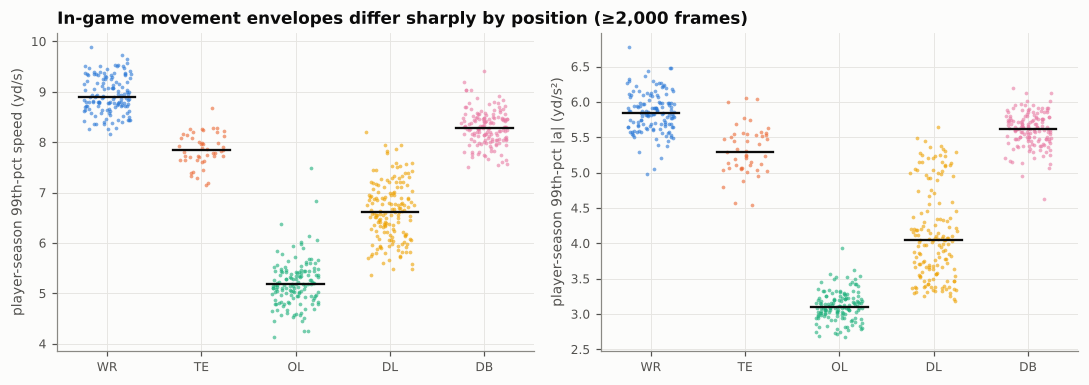

In [27]:
cr_pos = cr.select("nfl_id","combine_position")
pstat = pl.concat([load(f"game_tracking_{y}").join(load("games").filter(pl.col("season_type")!="PRE").select("game_id"), on="game_id")
         .filter(~pl.col("game_id").is_in(bad["game_id"].to_list()))
         .group_by("nfl_id").agg(pl.col("s").quantile(.99).alias("s_p99"), pl.col("s").max().alias("s_max"), pl.col("a").quantile(.99).alias("a_p99"), pl.len().alias("frames"))
         .with_columns(pl.lit(y).alias("season")).collect() for y in (2023,2024,2025)]).join(cr_pos, on="nfl_id")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col, lab in [(axes[0], "s_p99", "player-season 99th-pct speed (yd/s)"), (axes[1], "a_p99", "player-season 99th-pct |a| (yd/s²)")]:
    for i, p in enumerate(POS):
        v = pstat.filter((pl.col("combine_position")==p)&(pl.col("frames")>=2000))[col].to_numpy()
        ax.scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-.25,.25,len(v)), v, s=6, color=PCOL[p], alpha=.6, linewidths=0)
        ax.plot([i-.3, i+.3], [np.median(v)]*2, color=style.TEXT, lw=1.5)
    ax.set_xticks(range(len(POS)), POS); ax.set_ylabel(lab)
axes[0].set_title("In-game movement envelopes differ sharply by position (≥2,000 frames)", loc="left")
fig.tight_layout(); save(fig, "fig08_game_envelopes")

Example: all cohort players tracked on one play (raw field coordinates, yards; `play_direction` in `player_play` would be needed to normalise).

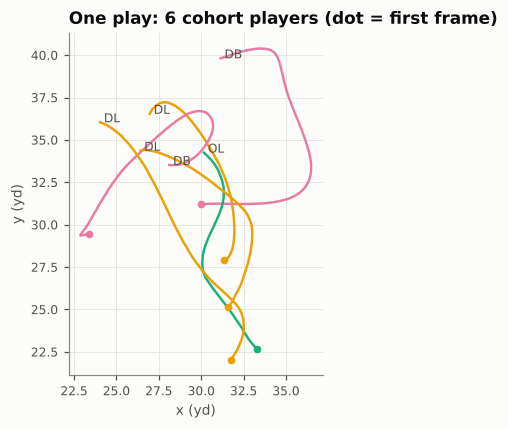

In [28]:
gt25 = load("game_tracking_2025")
gp = ppp.filter(pl.col("cohort_players_on_play")==6).row(0)
d = gt25.filter((pl.col("game_id")==gp[0])&(pl.col("play_id")==gp[1])).collect().join(cr_pos, on="nfl_id").sort("nfl_id","time")
fig, ax = plt.subplots(figsize=(8, 4))
for i, (nid, g) in enumerate(d.group_by("nfl_id", maintain_order=True)):
    p = g["combine_position"][0]
    ax.plot(g["x"], g["y"], color=PCOL[p], lw=1.6); ax.plot(g["x"][0], g["y"][0], "o", color=PCOL[p], ms=4)
    ax.text(g["x"][-1], g["y"][-1], f" {p}", fontsize=8, color=style.TEXT2)
sn = d.filter(pl.col("event")=="ball_snap")
ax.set_aspect("equal"); ax.set_xlabel("x (yd)"); ax.set_ylabel("y (yd)")
ax.set_title(f"One play: {d['nfl_id'].n_unique()} cohort players (dot = first frame)", loc="left")
fig.tight_layout(); save(fig, "fig09_example_play")

### Orientation, pre-snap coverage and football context available per position

In [29]:
g1 = load("game_tracking_2025").head(1_000_000).collect().filter(pl.col("s")>3)
od = np.abs(((g1["o"]-g1["dir"]).to_numpy()+180)%360-180)
print(f"o vs dir at s>3 yd/s (2025, first 1M rows): median |o-dir| = {np.median(od):.1f} deg; share > 90 deg (moving backwards, e.g. backpedal) = {(od>90).mean():.3f}")
k_ = ["game_id","play_id","nfl_id"]
pre = (load("game_tracking_2025").sort(k_+["time"]).with_columns(pl.int_range(pl.len()).over(k_).alias("i"))
       .filter(pl.col("event")=="ball_snap").group_by(k_).agg(pl.col("i").min().alias("pre_snap_frames")).collect())
print("pre-snap frames per player-play (2025):", {q: pre["pre_snap_frames"].quantile(q) for q in (0.05, 0.5, 0.95)}, "| share with 0:", round((pre["pre_snap_frames"]==0).mean(), 5))
print("combine BALL: attempts", CB["event_id"].n_unique(), "| ball frames aligned to a player frame:", CB.join(CP.select("event_id","time"), on=["event_id","time"]).height, "of", CB.height)
outcome_cols = ["route_ran","separation_at_pass_forward","cushion","pressure_allowed","time_to_pressure_allowed","player_get_off","time_to_pressure","coverage_assignment","tackle","blitzing"]
load("player_play").join(load("combine_results").select("nfl_id","combine_position"), on="nfl_id").group_by("combine_position").agg(
    [pl.len().alias("rows")] + [pl.col(c).is_not_null().mean().round(3).alias(c) for c in outcome_cols]).sort("combine_position").collect()

o vs dir at s>3 yd/s (2025, first 1M rows): median |o-dir| = 23.6 deg; share > 90 deg (moving backwards, e.g. backpedal) = 0.115


pre-snap frames per player-play (2025): {0.05: 9.0, 0.5: 10.0, 0.95: 10.0} | share with 0: 0.00035
combine BALL: attempts 551 | ball frames aligned to a player frame: 32095 of 32095


combine_position,rows,route_ran,separation_at_pass_forward,cushion,pressure_allowed,time_to_pressure_allowed,player_get_off,time_to_pressure,coverage_assignment,tackle,blitzing
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""DB""",84990,0.001,0.0,0.589,0.0,0.0,0.008,0.004,0.494,0.086,0.585
"""DL""",68235,0.0,0.0,0.069,0.0,0.0,0.635,0.051,0.45,0.064,0.551
"""OL""",107720,0.0,0.0,0.0,0.559,0.046,0.0,0.0,0.0,0.0,0.56
"""TE""",9866,1.0,0.877,0.786,0.051,0.003,0.0,0.0,0.0,0.003,0.996
"""WR""",43386,1.0,0.877,0.95,0.003,0.0,0.0,0.0,0.0,0.003,0.997


**Play-type selection by position.** `pass_result == ""` marks non-pass plays. WR/TE rows (in both `player_play` and tracking) contain **only dropback plays on which they ran a route**: no run plays and no blocking snaps. OL/DL/DB rows include run plays.

In [30]:
ppos = load("player_play").join(load("combine_results").select("nfl_id","combine_position"), on="nfl_id")
trk = load("game_tracking_2025").select("game_id","play_id","nfl_id").unique().join(ppos.select("game_id","play_id","nfl_id","combine_position","pass_result"), on=["game_id","play_id","nfl_id"])
pl.concat([ppos.group_by("combine_position").agg(pl.lit("player_play (all seasons)").alias("source"), pl.len().alias("rows"), (pl.col("pass_result")=="").mean().round(3).alias("share_non_pass_plays")),
           trk.group_by("combine_position").agg(pl.lit("tracking 2025").alias("source"), pl.len().alias("rows"), (pl.col("pass_result")=="").mean().round(3).alias("share_non_pass_plays"))]).sort("source","combine_position").collect()

combine_position,source,rows,share_non_pass_plays
str,str,u32,f64
"""DB""","""player_play (all seasons)""",84990,0.377
"""DL""","""player_play (all seasons)""",68235,0.414
"""OL""","""player_play (all seasons)""",107720,0.403
"""TE""","""player_play (all seasons)""",9866,0.0
"""WR""","""player_play (all seasons)""",43386,0.0
"""DB""","""tracking 2025""",42015,0.374
"""DL""","""tracking 2025""",35378,0.412
"""OL""","""tracking 2025""",52680,0.401
"""TE""","""tracking 2025""",4943,0.0


## 4 · Player identity matching
All files carry `nfl_id`. We do **not** assume it matches — we verify it with independent attributes.

In [31]:
P = load("players", lazy=False); CS = load("player_career_successes", lazy=False); PP = load("player_play", lazy=False)
j = P.join(cr, on="nfl_id", suffix="_c")
checks = {
  "nfl_id sets identical across players/combine_results/combine_tracking/career": ids["players"]==ids["combine_results"]==ids["combine_tracking"]==ids["player_career_successes"],
  "draft_year: players == combine_results": bool((j["draft_year"]==j["draft_year_c"]).all()),
  "draft_year: players == combine_tracking": bool(CP.select("nfl_id","draft_year").unique().join(P.select("nfl_id", pl.col("draft_year").alias("d")), on="nfl_id").select((pl.col("draft_year")==pl.col("d")).all()).item()),
  "combine date year == draft_year": bool(CP.select((pl.col("time").dt.year()==pl.col("draft_year")).all()).item()),
  "skill-drill family consistent with combine_position (LB drills -> DL only)": CPp.filter(pl.col("drill_type").str.starts_with("SKILL")).group_by("drill_type").agg(pl.col("combine_position").unique()).sort("drill_type").rows(),
  "nobody appears in game tracking before their draft year": all(load(f"game_tracking_{y}").select("nfl_id").unique().collect().join(P, on="nfl_id").filter(pl.col("draft_year")>y).height==0 for y in (2023,2024,2025)),
  "offense positions have ~0 defensive snaps": CS.join(cr_pos, on="nfl_id").group_by("combine_position").agg(pl.col("career_offensive_snaps").sum(), pl.col("career_defensive_snaps").sum()).sort("combine_position").rows(),
}
for k_, v in checks.items(): print("•", k_, "->", v)

• nfl_id sets identical across players/combine_results/combine_tracking/career -> True
• draft_year: players == combine_results -> True
• draft_year: players == combine_tracking -> True
• combine date year == draft_year -> True
• skill-drill family consistent with combine_position (LB drills -> DL only) -> [('SKILL_DRILLS_DB', ['DB']), ('SKILL_DRILLS_DL', ['DL']), ('SKILL_DRILLS_LB', ['DL']), ('SKILL_DRILLS_OL', ['OL']), ('SKILL_DRILLS_TE', ['TE']), ('SKILL_DRILLS_WR', ['WR'])]
• nobody appears in game tracking before their draft year -> True
• offense positions have ~0 defensive snaps -> [('DB', 27, 66889), ('DL', 1, 52608), ('OL', 86582, 0), ('TE', 19513, 0), ('WR', 60859, 0)]


In [32]:
print("combine_position × nfl_position (players.csv):")
j.group_by("combine_position","nfl_position").len().sort("combine_position","len", descending=[False, True])

combine_position × nfl_position (players.csv):


combine_position,nfl_position,len
str,str,u32
"""DB""","""CB""",60
"""DB""","""SS""",28
"""DB""","""FS""",25
"""DB""","""DB""",5
"""DB""","""ILB""",2
"""DB""","""MLB""",1
"""DB""","""RB""",1
"""DL""","""DT""",47
"""DL""","""DE""",36


In [33]:
gp_reg = PP.join(games.select("game_id","season_type"), on="game_id").filter(pl.col("season_type")=="REG").group_by("nfl_id").agg(pl.col("game_id").n_unique().alias("tracked_reg_games"))
gp_rp = PP.join(games.select("game_id","season_type"), on="game_id").filter(pl.col("season_type")!="PRE").group_by("nfl_id").agg(pl.col("game_id").n_unique().alias("tracked_regpost_games"))
cmpg = CS.join(gp_reg, on="nfl_id", how="left").join(gp_rp, on="nfl_id", how="left").fill_null(0)
print("career_games_active < tracked REG games (impossible if IDs match):", (cmpg["career_games_active"] < cmpg["tracked_reg_games"]).sum())
print("Pearson r(career_games_active, tracked REG games):", round(np.corrcoef(cmpg["career_games_active"], cmpg["tracked_reg_games"])[0,1], 3))
print("career_games_active - tracked REG+POST games, quantiles:", cmpg.select((pl.col("career_games_active")-pl.col("tracked_regpost_games")).quantile(q).alias(str(q)) for q in (0,.25,.5,.75,.95,1)).row(0))

career_games_active < tracked REG games (impossible if IDs match): 0
Pearson r(career_games_active, tracked REG games): 0.884
career_games_active - tracked REG+POST games, quantiles: (-6.0, 0.0, 3.0, 9.0, 22.0, 47.0)


`career_games_active` is never smaller than the number of tracked regular-season games, and the two correlate strongly. The usual excess means a player can be active without a single tracked snap here (e.g. special-teams-only snaps, which `player_play` appears not to cover; cf. `career_special_teams_snaps`). The small negative minimum against REG+POST suggests career totals may exclude the postseason. These definitions must be confirmed on the Kaggle data page before using career fields as outcomes.

Duplicate display names — resolved by `nfl_id` (different people):

In [34]:
P.filter(pl.col("display_name").is_duplicated()).select("nfl_id","display_name","draft_year","nfl_position","college_conference","draft_round").sort("display_name")

nfl_id,display_name,draft_year,nfl_position,college_conference,draft_round
i64,str,i64,str,str,i64
56107,"""Anthony Johnson""",2023,"""FS""","""Big Twelve Conference""",7
56629,"""Anthony Johnson""",2023,"""CB""","""Atlantic Coast Conference""",null
56363,"""Leonard Taylor""",2023,"""TE""","""Big Twelve Conference""",null
57434,"""Leonard Taylor""",2024,"""DT""","""Atlantic Coast Conference""",null


### Coverage by position

In [35]:
reg_plays = PP.join(games, on="game_id").filter(pl.col("season_type")=="REG").group_by("nfl_id").agg(pl.len().alias("reg_plays"))
cov = (cr.select("nfl_id","combine_position","draft_year").join(reg_plays, on="nfl_id", how="left")
       .join(PP.select("nfl_id").unique().with_columns(pl.lit(True).alias("any_game")), on="nfl_id", how="left")
       .join(CS.select("nfl_id","career_games_active"), on="nfl_id").fill_null(0)
       .with_columns(pl.col("any_game").cast(pl.Boolean)))
covtab = cov.group_by("combine_position").agg(pl.len().alias("combine_participants"), pl.col("any_game").sum().alias("any_game_tracking"),
        (pl.col("reg_plays")>0).sum().alias("REG_tracking"), (pl.col("reg_plays")>=100).sum().alias("REG_100plus_plays"),
        (pl.col("career_games_active")>0).sum().alias("career_games_gt0")).sort("combine_position")
covtab = pl.concat([covtab, covtab.select(pl.lit("ALL").alias("combine_position"), *[pl.col(c).sum() for c in covtab.columns[1:]])])
covtab.with_columns((100*pl.col("REG_100plus_plays")/pl.col("combine_participants")).round(1).alias("pct_REG_100plus"))

combine_position,combine_participants,any_game_tracking,REG_tracking,REG_100plus_plays,career_games_gt0,pct_REG_100plus
str,u32,u32,u32,u32,u32,f64
"""DB""",122,118,96,73,101,59.8
"""DL""",118,115,98,77,100,65.3
"""OL""",121,120,91,69,101,57.0
"""TE""",42,38,33,21,34,50.0
"""WR""",107,106,83,63,86,58.9
"""ALL""",510,497,401,303,422,59.4


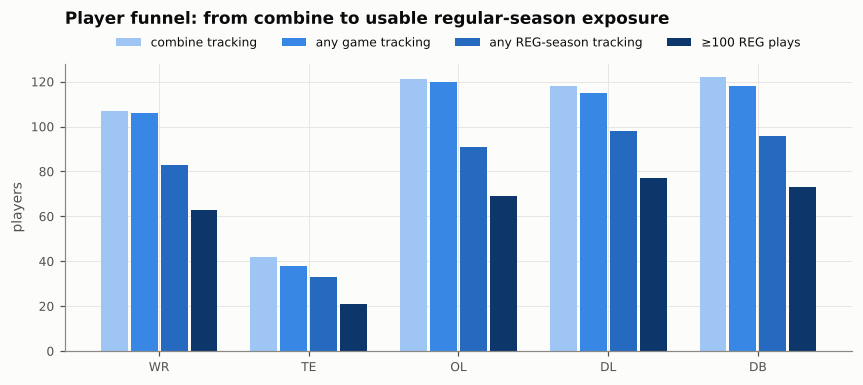

In [36]:
stages = ["combine_participants","any_game_tracking","REG_tracking","REG_100plus_plays"]
lab = ["combine tracking","any game tracking","any REG-season tracking","≥100 REG plays"]
ramp = [style.SEQ_BLUE[i] for i in (1, 3, 4, 6)]
ct_ = covtab.filter(pl.col("combine_position")!="ALL")
fig, ax = plt.subplots(figsize=(8, 3.6)); w = .2
for k_, (st, l, c) in enumerate(zip(stages, lab, ramp)):
    vals = [ct_.filter(pl.col("combine_position")==p)[st][0] for p in POS]
    ax.bar(np.arange(len(POS)) + (k_-1.5)*w, vals, width=w-.02, color=c, label=l)
ax.set_xticks(range(len(POS)), POS); ax.set_ylabel("players"); ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(.5, 1.13))
ax.set_title("Player funnel: from combine to usable regular-season exposure", loc="left", pad=26)
fig.tight_layout(); save(fig, "fig10_coverage_funnel")

### Exposure and outcome censoring by draft class

┌────────────┬─────┬───────────────┬─────────────┬──────────────┐
│ draft_year ┆ len ┆ median_starts ┆ any_all_pro ┆ any_pro_bowl │
│ ---        ┆ --- ┆ ---           ┆ ---         ┆ ---          │
│ i64        ┆ u32 ┆ f64           ┆ u32         ┆ u32          │
╞════════════╪═════╪═══════════════╪═════════════╪══════════════╡
│ 2023       ┆ 160 ┆ 5.0           ┆ 5           ┆ 7            │
│ 2024       ┆ 177 ┆ 2.0           ┆ 1           ┆ 3            │
│ 2025       ┆ 173 ┆ 0.0           ┆ 1           ┆ 1            │
└────────────┴─────┴───────────────┴─────────────┴──────────────┘


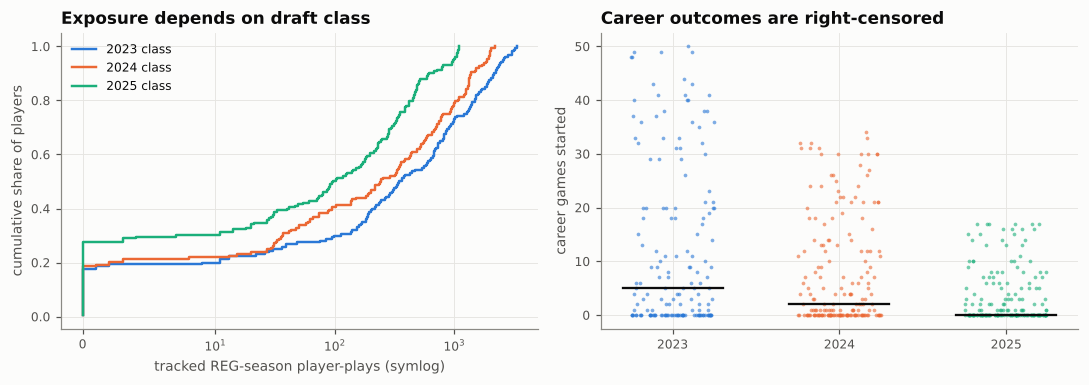

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for i, y in enumerate((2023, 2024, 2025)):
    v = np.sort(cov.filter(pl.col("draft_year")==y)["reg_plays"].to_numpy())
    axes[0].step(v, np.arange(1, len(v)+1)/len(v), where="post", color=style.SERIES[i], label=f"{y} class")
    g = CS.join(P.select("nfl_id","draft_year"), on="nfl_id").filter(pl.col("draft_year")==y)["career_games_started"].to_numpy()
    axes[1].scatter(np.full(len(g), i) + np.random.default_rng(i).uniform(-.25,.25,len(g)), g, s=6, color=style.SERIES[i], alpha=.6, linewidths=0)
    axes[1].plot([i-.3, i+.3], [np.median(g)]*2, color=style.TEXT, lw=1.5)
axes[0].set_xscale("symlog", linthresh=10); axes[0].set_xlabel("tracked REG-season player-plays (symlog)"); axes[0].set_ylabel("cumulative share of players")
axes[0].legend(); axes[0].set_title("Exposure depends on draft class", loc="left")
axes[1].set_xticks(range(3), ["2023","2024","2025"]); axes[1].set_ylabel("career games started"); axes[1].set_title("Career outcomes are right-censored", loc="left")
fig.tight_layout(); save(fig, "fig11_exposure_censoring")
print(CS.join(P.select("nfl_id","draft_year"), on="nfl_id").group_by("draft_year").agg(pl.len(), pl.col("career_games_started").median().alias("median_starts"),
      (pl.col("ap_all_pro_1st_team")+pl.col("ap_all_pro_2nd_team")>0).sum().alias("any_all_pro"), (pl.col("pro_bowl_original_ballot")>0).sum().alias("any_pro_bowl")).sort("draft_year"))

## 5 · Research-opportunity probes (descriptive only)
These are *feasibility probes* — can the data even measure combine→game translation? — not hypothesis tests. No model is fit; one descriptive correlation per position, with n shown.

position,n,spearman_rho
str,i64,f64
"""WR""",68,0.590695
"""TE""",24,0.489672
"""OL""",67,0.140139
"""DL""",75,0.669749
"""DB""",75,0.213823


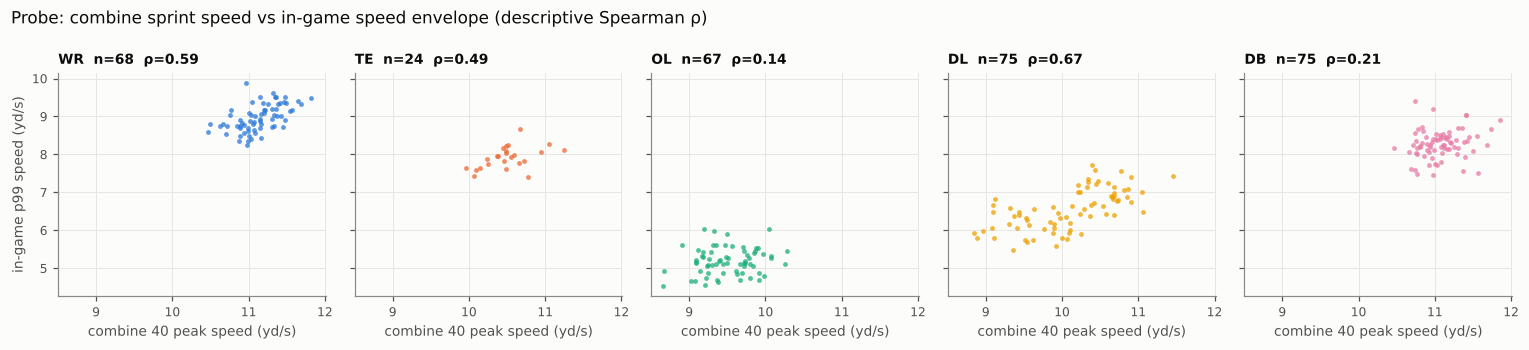

In [38]:
# combine: max speed reached in the 40 (best attempt); game: player's p99 speed over REG+POST (pooled seasons, ≥2,000 frames)
c_vmax = CP.filter(pl.col("drill_type")=="FORTY_YARD_DASH").group_by("nfl_id").agg(pl.col("s").max().alias("combine_40_vmax"))
g_all = pstat.group_by("nfl_id","combine_position").agg(((pl.col("s_p99")*pl.col("frames")).sum()/pl.col("frames").sum()).alias("game_s_p99"), pl.col("frames").sum()).filter(pl.col("frames")>=2000)
tr = c_vmax.join(g_all, on="nfl_id")
fig, axes = plt.subplots(1, 5, figsize=(14, 3.2), sharex=True, sharey=True)
res = []
for ax, p in zip(axes, POS):
    d = tr.filter(pl.col("combine_position")==p)
    r_s = d.select(pl.corr("combine_40_vmax","game_s_p99", method="spearman")).item() if d.height > 3 else float("nan")
    res.append((p, d.height, r_s))
    ax.scatter(d["combine_40_vmax"], d["game_s_p99"], s=10, color=PCOL[p], alpha=.75, linewidths=0)
    ax.set_title(f"{p}  n={d.height}  ρ={r_s:.2f}", fontsize=9, loc="left"); ax.set_xlabel("combine 40 peak speed (yd/s)")
axes[0].set_ylabel("in-game p99 speed (yd/s)")
fig.suptitle("Probe: combine sprint speed vs in-game speed envelope (descriptive Spearman ρ)", x=.01, ha="left", fontsize=11)
fig.tight_layout(); save(fig, "fig12_probe_speed_translation")
pl.DataFrame(res, schema=["position","n","spearman_rho"], orient="row")

**Interpretation (bounded).** In-game top speed is constrained by role (OL rarely sprint), so a weak OL association is expected and not evidence against translation. Any real analysis must adjust for role, play type, opportunity and multiple comparisons; this probe only shows the linkage is measurable.

**Deceleration capacity is observable in both domains.** Distribution of the strongest derived braking (min signed ds/dt) per attempt / player-play:

┌──────────────────┬──────────┐
│ drill_type       ┆ min_dsdt │
│ ---              ┆ ---      │
│ str              ┆ f64      │
╞══════════════════╪══════════╡
│ SHORT_SHUTTLE    ┆ -7.87    │
│ THREE_CONE_DRILL ┆ -5.88    │
│ SKILL_DRILLS_LB  ┆ -5.18    │
│ SKILL_DRILLS_DL  ┆ -3.58    │
│ SKILL_DRILLS_DB  ┆ -2.97    │
│ SKILL_DRILLS_OL  ┆ -2.55    │
│ SKILL_DRILLS_WR  ┆ -2.26    │
│ SKILL_DRILLS_TE  ┆ -1.7     │
│ FORTY_YARD_DASH  ┆ -0.33    │
└──────────────────┴──────────┘


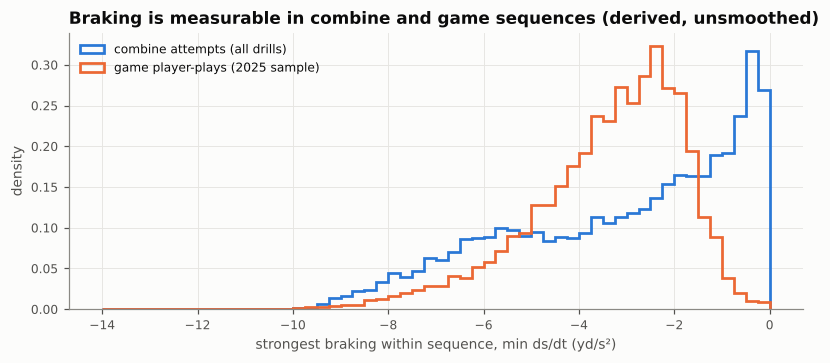

In [39]:
cbrake = ck.group_by("event_id","drill_type").agg(pl.col("a_tan").min().alias("min_dsdt")).drop_nulls()
gbrake = gk.group_by("k").agg(pl.col("a_tan").min().alias("min_dsdt")).drop_nulls()
fig, ax = plt.subplots(figsize=(7.5, 3.4))
bins = np.linspace(-14, 0, 57)
for i, (lab_, v) in enumerate([("combine attempts (all drills)", cbrake["min_dsdt"]), ("game player-plays (2025 sample)", gbrake["min_dsdt"])]):
    ax.hist(v.to_numpy(), bins=bins, density=True, histtype="step", lw=1.8, color=style.SERIES[i], label=lab_)
ax.set_xlabel("strongest braking within sequence, min ds/dt (yd/s²)"); ax.set_ylabel("density"); ax.legend(loc="upper left")
ax.set_title("Braking is measurable in combine and game sequences (derived, unsmoothed)", loc="left")
fig.tight_layout(); save(fig, "fig13_braking")
print(cbrake.group_by("drill_type").agg(pl.col("min_dsdt").median().round(2)).sort("min_dsdt"))

Raw finite differences amplify positional noise; magnitudes above are unsmoothed upper bounds and the filtering choice (Savitzky–Golay, Kalman, splines) will itself be a methodological decision in Phase 2.

### Sample-size reality check

In [40]:
n_tab = cov.filter(pl.col("reg_plays")>=100).group_by("combine_position").agg(pl.len().alias("n_players"))
n_tab = n_tab.with_columns((2.8/ (pl.col("n_players")-3).sqrt()).alias("approx_min_detectable_r"))
print("Approx. smallest correlation detectable at α=0.05, power 0.8 (Fisher z: r ≈ tanh(2.8/√(n−3))):")
n_tab.with_columns(pl.col("approx_min_detectable_r").tanh().round(2)).sort("combine_position")

Approx. smallest correlation detectable at α=0.05, power 0.8 (Fisher z: r ≈ tanh(2.8/√(n−3))):


combine_position,n_players,approx_min_detectable_r
str,u32,f64
"""DB""",73,0.32
"""DL""",77,0.31
"""OL""",69,0.33
"""TE""",21,0.58
"""WR""",63,0.35


## 6 · Summary
See `research_notes/` for the written inventory, matching report and research-opportunity assessment. Phase 2 has **not** started.